In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.optimize import linear_sum_assignment
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, confusion_matrix, accuracy_score

In [2]:
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target  # 3 wine cultivars (used ONLY for evaluation)
print("Shape:", X.shape)
print("Class balance:", dict(zip(wine.target_names, np.bincount(y))))

Shape: (178, 13)
Class balance: {np.str_('class_0'): np.int64(59), np.str_('class_1'): np.int64(71), np.str_('class_2'): np.int64(48)}


In [3]:
X_scaled = StandardScaler().fit_transform(X)

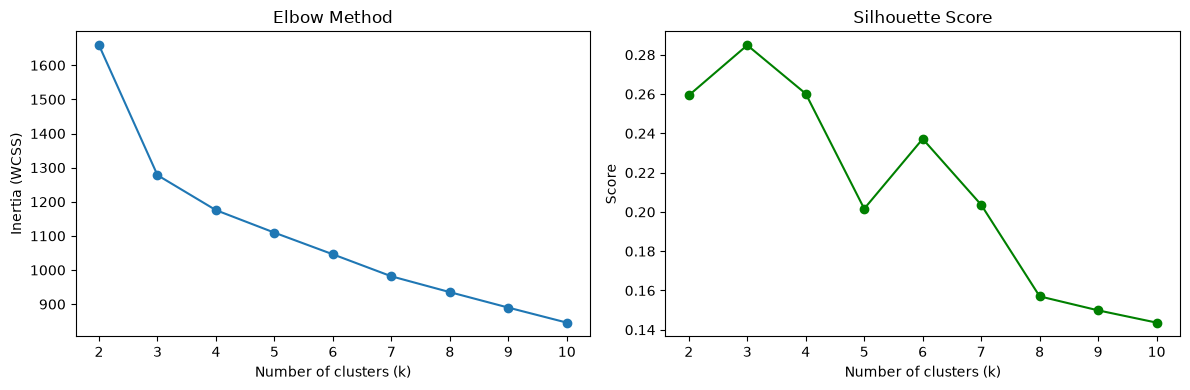

In [4]:
k_range = range(2, 11)
inertias, silhouettes = [], []
for k in k_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_range, inertias, "o-")
ax[0].set(title="Elbow Method", xlabel="Number of clusters (k)", ylabel="Inertia (WCSS)")
ax[1].plot(k_range, silhouettes, "o-", color="green")
ax[1].set(title="Silhouette Score", xlabel="Number of clusters (k)", ylabel="Score")
plt.tight_layout()
plt.show()

In [5]:
kmeans = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42)
raw_clusters = kmeans.fit_predict(X_scaled)

In [6]:
cm = confusion_matrix(y, raw_clusters)
row_ind, col_ind = linear_sum_assignment(-cm)
mapping = {col: row for row, col in zip(row_ind, col_ind)}
clusters = np.array([mapping[c] for c in raw_clusters])

print("\n--- Evaluation ---")
print(f"Silhouette score:    {silhouette_score(X_scaled, clusters):.3f}")
print(f"Adjusted Rand Index: {adjusted_rand_score(y, clusters):.3f}")
print(f"Accuracy (aligned):  {accuracy_score(y, clusters):.3f}")
print("\nConfusion matrix (rows = true, cols = cluster):")
print(confusion_matrix(y, clusters))


--- Evaluation ---
Silhouette score:    0.285
Adjusted Rand Index: 0.897
Accuracy (aligned):  0.966

Confusion matrix (rows = true, cols = cluster):
[[59  0  0]
 [ 3 65  3]
 [ 0  0 48]]


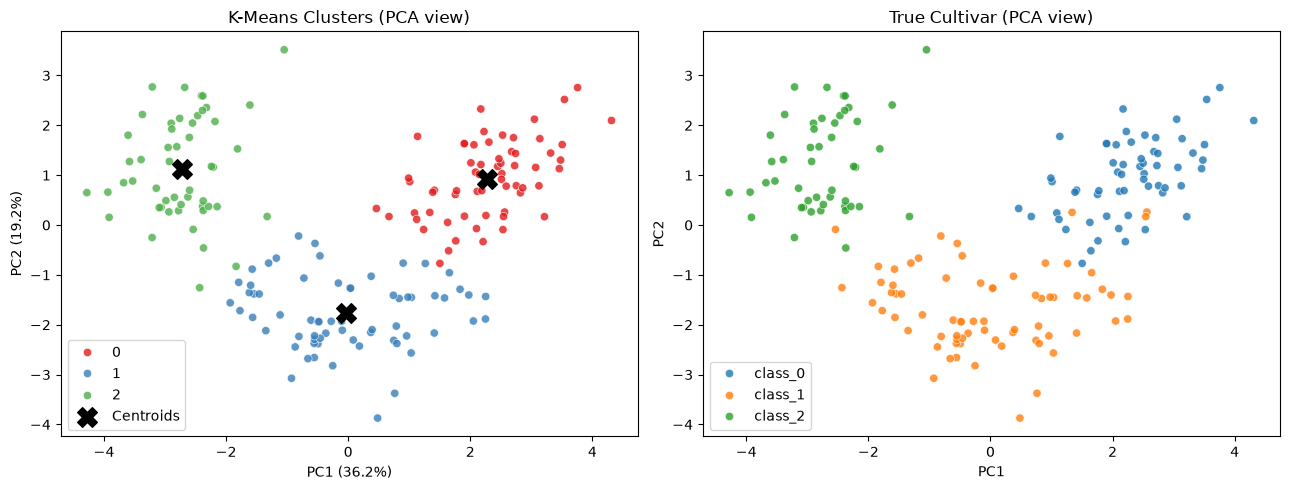

In [7]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
centers_pca = pca.transform(kmeans.cluster_centers_)
centers_pca = centers_pca[[col for col, row in sorted(mapping.items(), key=lambda t: t[1])]]

cultivars = np.array(wine.target_names)[y]
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clusters, palette="Set1", alpha=0.8, ax=ax[0])
ax[0].scatter(centers_pca[:, 0], centers_pca[:, 1], c="black", marker="X", s=200, label="Centroids")
ax[0].set(title="K-Means Clusters (PCA view)",
          xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%})",
          ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax[0].legend()
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=cultivars, alpha=0.8, ax=ax[1])
ax[1].set(title="True Cultivar (PCA view)", xlabel="PC1", ylabel="PC2")
plt.tight_layout()
plt.show()

In [8]:
profile = X.copy()
profile["cluster"] = clusters
print("\n--- Mean of key features per cluster ---")
print(profile.groupby("cluster")[["alcohol", "flavanoids", "color_intensity", "proline"]].mean().round(2))


--- Mean of key features per cluster ---
         alcohol  flavanoids  color_intensity  proline
cluster                                               
0          13.68        3.00             5.45  1100.23
1          12.25        2.05             2.97   510.17
2          13.13        0.82             7.23   619.06


In [9]:
raw_km = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X)
print(f"\nARI without scaling: {adjusted_rand_score(y, raw_km):.3f}")
print(f"ARI with scaling:    {adjusted_rand_score(y, raw_clusters):.3f}")


ARI without scaling: 0.371
ARI with scaling:    0.897
